# Universal source coefficients

Read the exact coefficient expressions and their saved decimal values from the
YAML archive in this directory. `utils.get` does not regenerate the coefficients
or evaluate their special functions. See [README.md](README.md) for conventions,
precision and the archive layout.

In [1]:
from pathlib import Path
import sys
import sympy as sp
from IPython.display import display

# Support execution from the repository root or a notebook directory.
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "utils/get.py").is_file() and (p / "results").is_dir()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside the SRI repository.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from utils import get
sp.init_printing()


## Select a coefficient

A pattern `(j_1,...,j_m)` has slow-roll weight `m+sum(j_i)`. Permutations
select the same coefficient; `(0,1,1)` is a mixed coefficient of weight five.

In [2]:
pattern = (0, 1, 1)


## Exact universal coefficient

The full expression is reconstructed from its YAML definition. The quoted
decimal values below are read separately and do not require evaluating the
special functions in the expression.

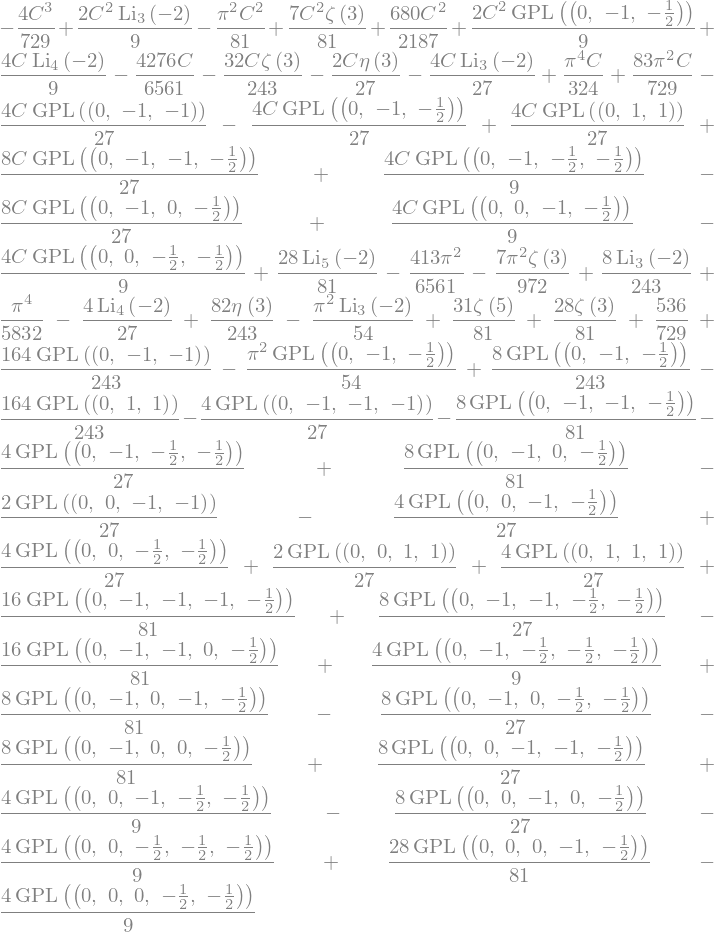

Saved analytic evaluation: 0.00424504144990432475268140
Independent mode equation: 0.0042450414499043245


In [3]:
chi = get.coefficient(*pattern)
display(chi)
print("Saved analytic evaluation:", get.value(*pattern))
print("Independent mode equation:", get.value(*pattern, source="mode_equation"))
assert chi == get.coefficient(*reversed(pattern))


## A short analytic family

Coefficients from the shorter families use `C = EulerGamma + log(2) - 2`,
powers of pi and standard special functions. The result is an exact SymPy
expression; it can be printed as LaTeX without a numerical evaluation.

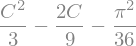

In [4]:
short = get.coefficient(1)
display(short)
latex_coefficient = sp.latex(short)


## Available coefficients

The archive contains all 138 coefficients through weight ten, including 67 mixed
patterns. `get.value` returns the stored `Decimal`, preserving its quoted digits;
the independent mode-equation accuracy is determined by its integration error.
A missing pattern raises an error without starting a calculation.

Use `root=PATH` to select an alternative `results/` directory and
`get.clear_cache()` to release the loaded families and expressions.
Examples for spectra and consistency relations are in
[the archived-results notebook](../../notebooks/03_archived_results.ipynb).